###  Task 1: Data Cleaning and Preprocessing.

In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
df=pd.read_csv("Telco_Customer_Churn_Dataset .csv")

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
df.drop(columns=['customerID'],inplace=True) 

In [7]:
df['TotalCharges']= pd.to_numeric(df['TotalCharges'], errors='coerce')

##### Handle missing values in the dataset

In [8]:
df['Senior Citizen']= df['SeniorCitizen'].fillna(df['SeniorCitizen'].median())

In [9]:
df['tenure']= df['tenure'].fillna(df['tenure'].median())

In [10]:
df['MonthlyCharges']= df['MonthlyCharges'].fillna(df['MonthlyCharges'].median())

In [11]:
df['TotalCharges']= df['TotalCharges'].fillna(df['TotalCharges'].median())

In [12]:
df['MonthlyCharges'].dtype

dtype('float64')

##### Convert categorical variables into numerical representations using one-hot encoding

In [13]:
df_encoded= pd.get_dummies(df, dtype=int)

In [14]:
df_encoded.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Senior Citizen,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn_No,Churn_Yes
0,0,1,29.85,29.85,0,1,0,0,1,1,...,0,0,0,1,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,0,1,1,0,1,...,1,0,1,0,0,0,0,1,1,0
2,0,2,53.85,108.15,0,0,1,1,0,1,...,0,0,0,1,0,0,0,1,0,1
3,0,45,42.30,1840.75,0,0,1,1,0,1,...,1,0,1,0,1,0,0,0,1,0
4,0,2,70.70,151.65,0,1,0,1,0,1,...,0,0,0,1,0,0,1,0,0,1


### Task 2: Exploratory Data Analysis (EDA)

In [15]:
import matplotlib.pyplot as plt

In [16]:
counts=df['Churn'].value_counts()

##### Visualize the overall churn rate

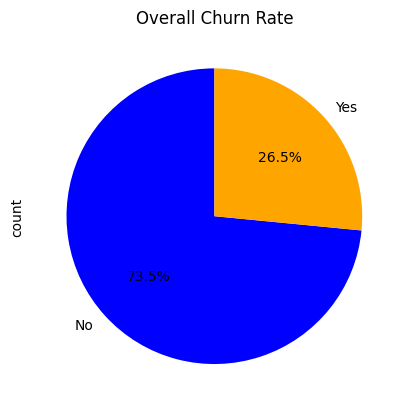

In [17]:
counts.plot.pie(autopct='%1.1f%%',startangle=90,colors=['blue','orange'])
plt.title('Overall Churn Rate')
plt.show()

##### Explore customer distribution by demographics

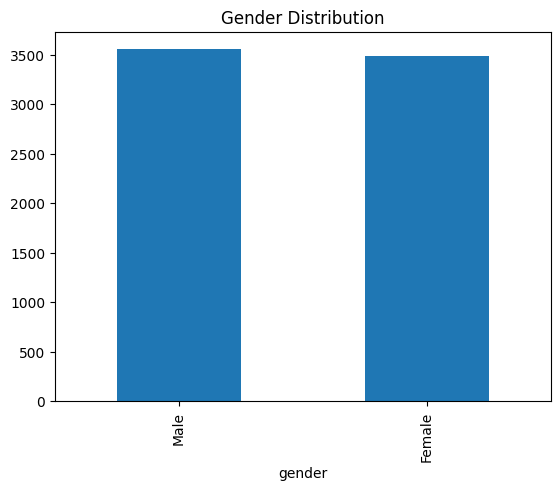

In [18]:
df['gender'].value_counts().plot(kind='bar')
plt.title('Gender Distribution')
plt.show()

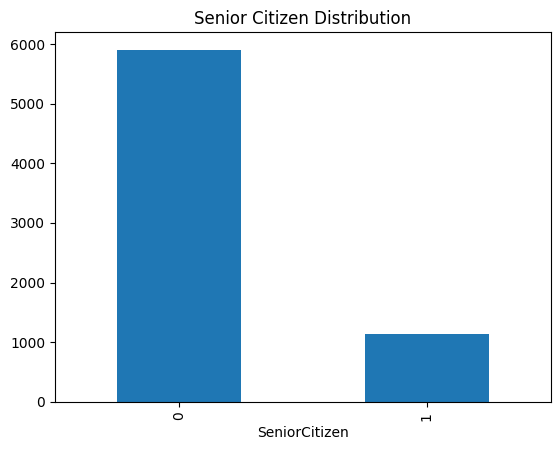

In [19]:
df['SeniorCitizen'].value_counts().plot(kind='bar')
plt.title('Senior Citizen Distribution')
plt.show()

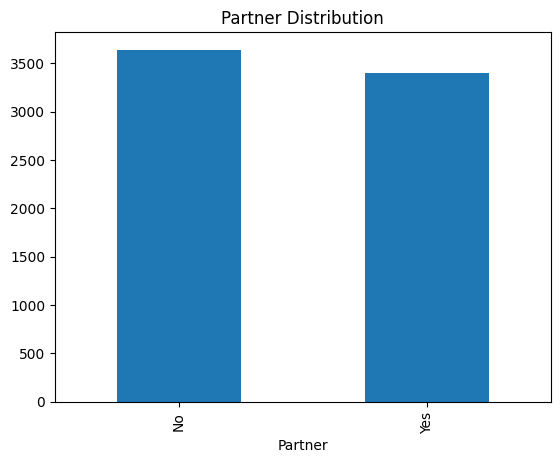

In [20]:
df['Partner'].value_counts().plot(kind='bar')
plt.title('Partner Distribution')
plt.show()

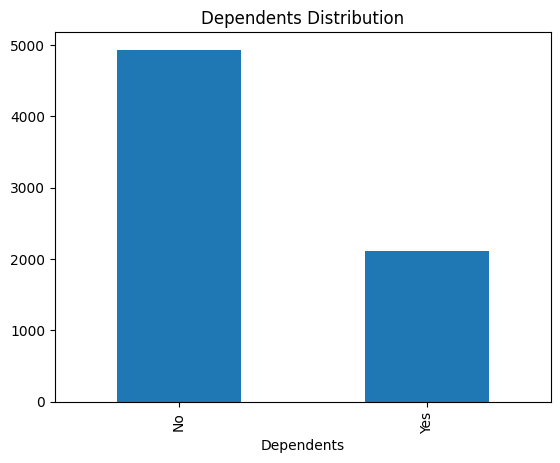

In [21]:
df['Dependents'].value_counts().plot(kind='bar')
plt.title('Dependents Distribution')
plt.show()

##### Analyze tenure distribution

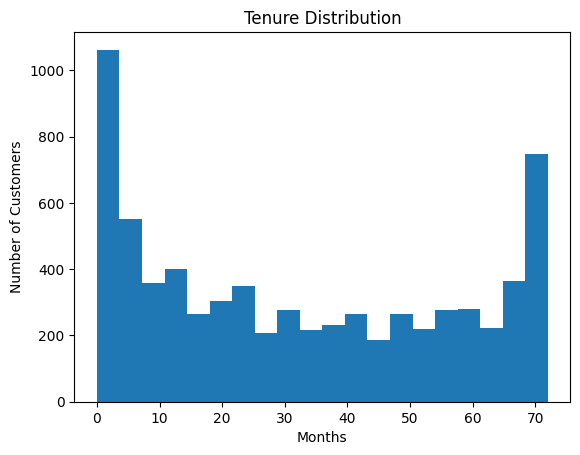

In [22]:
df['tenure'].plot(kind='hist', bins=20)
plt.title('Tenure Distribution')
plt.xlabel('Months')
plt.ylabel('Number of Customers')
plt.show()

##### Investigate the relationship between churn and contract types/payment methods

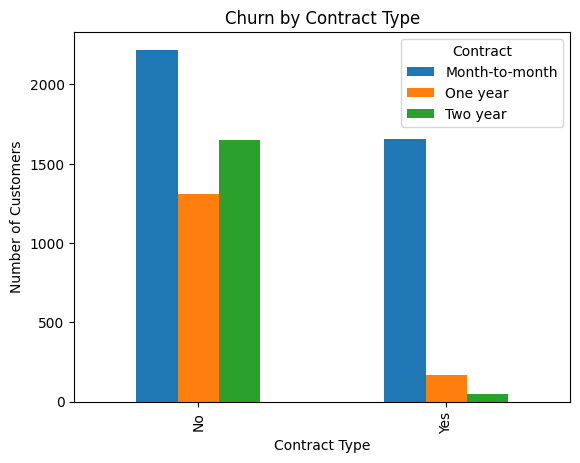

In [23]:
pd.crosstab(df['Churn'], df['Contract']).plot(kind='bar')
plt.title('Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()


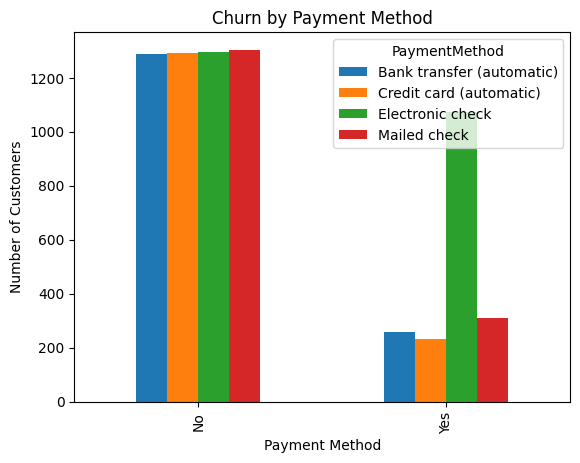

In [24]:
pd.crosstab(df['Churn'], df['PaymentMethod']).plot(kind='bar')
plt.title('Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.show()


### Task 3: Customer Segmentation


In [25]:
contract={
    'Month-to-month':1,
    'One year':2,
    'Two year':3
}
df['Contract_score']=df['Contract'].map(contract)

In [26]:
df['R_rank']=df['tenure'].rank(ascending=True)

In [27]:
df['F_rank']=df['MonthlyCharges'].rank(ascending=True)

In [28]:
df['M_rank']=df['Contract_score'].rank(ascending=True)

In [29]:
df['R_rank_norm'] = (df['R_rank'] / df['R_rank'].max()) * 100

In [30]:
df['F_rank_norm'] = (df['F_rank'] / df['F_rank'].max()) * 100

In [31]:
df['M_rank_norm'] = (df['M_rank'] / df['M_rank'].max()) * 100


In [32]:
df.drop(columns=['R_rank','F_rank','M_rank','Contract_score'],inplace=True)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Senior Citizen,R_rank_norm,F_rank_norm,M_rank_norm
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,4.633880,23.377822,31.278244
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,One year,No,Mailed check,56.95,1889.50,No,0,56.422587,39.415022,74.435119
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0,10.834244,35.517535,31.278244
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,One year,No,Bank transfer (automatic),42.30,1840.75,No,0,66.564663,26.835155,74.435119
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0,10.834244,50.759619,31.278244


In [33]:
df['RFM_Score']=(df['R_rank_norm']+df['F_rank_norm']+df['M_rank_norm'])/3
df['RFM_Score'].head(10)

0    19.763315
1    56.757576
2    25.876674
3    55.944979
4    30.957369
5    47.418036
6    49.372799
7    27.472810
8    58.046617
9    65.682892
Name: RFM_Score, dtype: float64

In [34]:
conditions=[
    df['RFM_Score'] > 65,
    df['RFM_Score'] > 50,
    df['RFM_Score'] > 25
]

choices=['Top Customers','Medium Value Customer','low value customer']
df['Customer_segmentation']=np.select(conditions, choices, default='At risk customer')

In [35]:
pd.crosstab(
    df['Customer_segmentation'],
    df['Churn'],
    normalize='index'
)*100

Churn,No,Yes
Customer_segmentation,,
At risk customer,63.262411,36.737589
Medium Value Customer,78.271919,21.728081
Top Customers,90.240314,9.759686
low value customer,60.770642,39.229358


#### The higher the segmentation score based on tenure, monthly charges, and contract type, the lower the churn rate. Customers with longer tenure, higher monthly charges, and longer contracts are less likely to churn.

### Task 4: Churn Prediction Model


In [36]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [37]:

X = df_encoded.drop(columns=['Churn_Yes', 'Churn_No'])
y = df_encoded['Churn_Yes']

In [38]:
X_train, X_test ,y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [39]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [40]:
y_pred = model.predict(X_test)

In [41]:
accuracy_score(y_test , y_pred)

0.8211497515968772

In [42]:
confusion_matrix(y_test, y_pred)

array([[932, 104],
       [148, 225]])

In [43]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.68      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.82      0.82      0.82      1409



### Task 5: Customer Retention Strategies

##### Proposing data-driven strategies to reduce churn

###### Offer discounts for customers to switch from month-to-month to one-year or two-year contracts.
###### Offer personalized discounts to customers with high monthly charges.
###### Offer alternatives to switch payment methods.

##### Identifing key factors influencing churn and suggesting actions

###### The first factor: Month-to-month contract: we can offer discounts for long-term contracts.
######  The second: Electronic check users : we can offer incentives to switch payment methods.
###### The third : High monthly charges: we can provide loyalty discounts

In [44]:
df['LTV']= df['MonthlyCharges']*df['tenure']

In [45]:
print(df['LTV'])

0         29.85
1       1936.30
2        107.70
3       1903.50
4        141.40
         ...   
7038    2035.20
7039    7430.40
7040     325.60
7041     297.60
7042    6972.90
Name: LTV, Length: 7043, dtype: float64


In [46]:
high_value_customer= df[df['LTV'] > df['LTV'].median()]
high_value_customer_at_risk= high_value_customer[high_value_customer['Churn']=='Yes']
print(high_value_customer_at_risk)

      gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
8     Female              0     Yes         No      28          Yes   
13      Male              0      No         No      49          Yes   
26      Male              0     Yes        Yes      47          Yes   
38      Male              0      No         No      34          Yes   
51    Female              0      No         No      15          Yes   
...      ...            ...     ...        ...     ...          ...   
6993  Female              1     Yes         No      50          Yes   
6996  Female              0     Yes        Yes      41          Yes   
7006    Male              0      No         No      40          Yes   
7009    Male              0      No         No      23          Yes   
7034  Female              0      No         No      67          Yes   

     MultipleLines InternetService OnlineSecurity OnlineBackup  ...  \
8              Yes     Fiber optic             No           No  ...   
13   

### Task 6: Visualisation

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

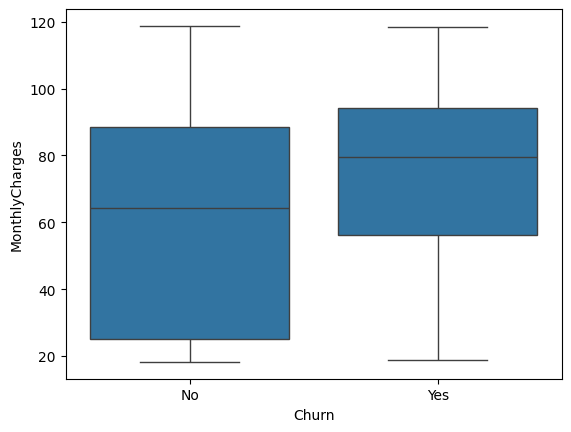

In [48]:
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.show()

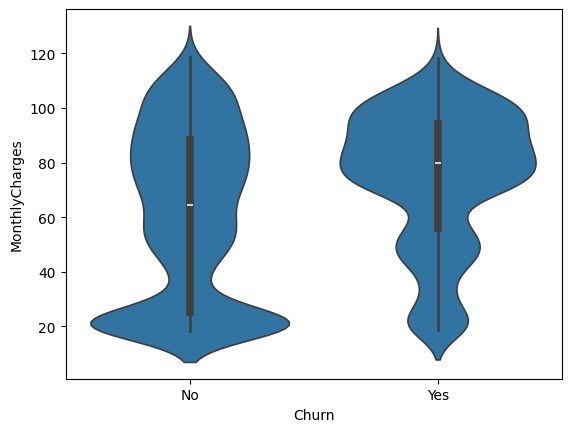

In [49]:
sns.violinplot(x='Churn', y='MonthlyCharges', data=df)
plt.show()

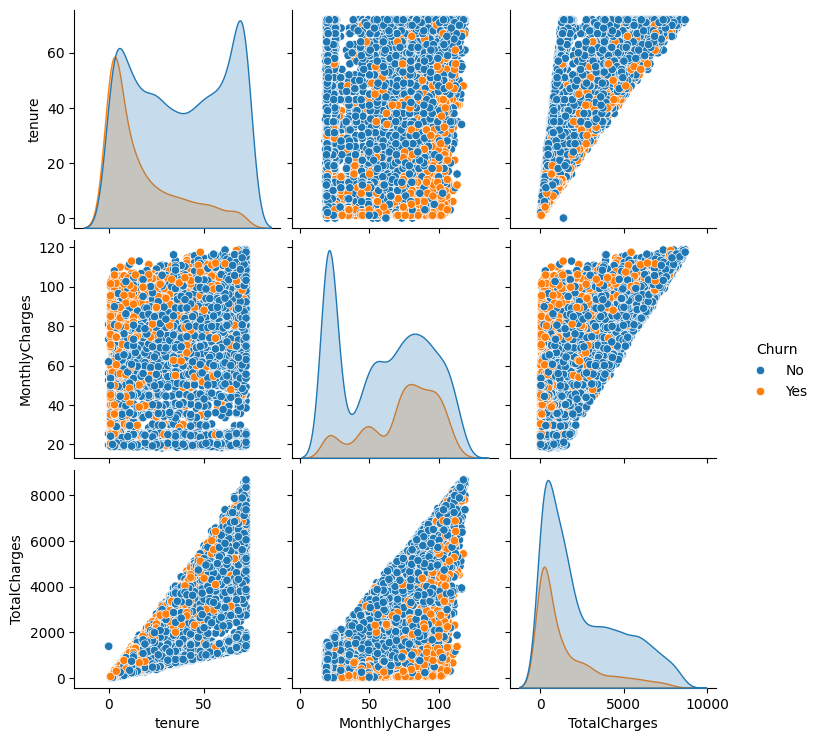

In [50]:
sns.pairplot(df[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']], hue='Churn')
plt.show()